# 04 - Deep learning: MLP (ANN) and CNN  *(no TensorFlow needed)*
This version of the notebook works on PCs where **TensorFlow is blocked** (e.g. Windows App Control).

| Model | Library | Idea |
|---|---|---|
| MLP / ANN | scikit-learn (`MLPClassifier`) | flatten the RGB pixels -> fully-connected layers |
| CNN | PyTorch (**optional**) | convolution filters learn local patterns |

* The **MLP always runs** (scikit-learn is already installed).
* The **CNN section runs only if PyTorch can be imported**. If it is missing or blocked, that cell prints a message and is skipped - the rest of the project is unaffected.

Both use the **same train/test split** as notebook 03 and are scored with the same `evaluate()` function.

In [3]:
import sys; sys.path.append("..")          # lets the notebook import src/common.py
from src.common import *
import matplotlib.pyplot as plt, numpy as np, pandas as pd
print("Project root:", ROOT)
print("QUICK mode:", QUICK)
import time, joblib
from sklearn.neural_network import MLPClassifier

X_train, X_test, y_train, y_test = load_split()
Xtr = X_train.reshape(len(X_train), -1).astype("float32") / 255.0     # (N, 12288) pixels scaled to 0-1
Xte = X_test.reshape(len(X_test), -1).astype("float32") / 255.0
print("train", Xtr.shape, "test", Xte.shape, "| epochs (max):", EPOCHS)

Project root: C:\Users\ASUS\Desktop\image_classification_project
QUICK mode: False
train (5519, 12288) test (1380, 12288) | epochs (max): {'mlp': 30, 'cnn': 25, 'resnet': 8, 'vgg': 8}


## 1 - MLP / ANN
![MLP](../docs/model_steps/07_mlp_ann.png)

Flatten 64x64x3 = 12,288 numbers -> Dense 512 -> Dense 256 -> softmax(8). Optimiser Adam, early stopping on a 15 % validation part of the training set.
A MLP ignores the 2-D structure of the image, so it is usually clearly weaker than a CNN.

In [4]:
mlp = MLPClassifier(hidden_layer_sizes=(512, 256), activation="relu", solver="adam",
                    alpha=1e-4, batch_size=64, learning_rate_init=1e-3,
                    max_iter=EPOCHS["mlp"], early_stopping=True, validation_fraction=0.15,
                    n_iter_no_change=5, random_state=SEED, verbose=True)
t = time.time(); mlp.fit(Xtr, y_train); tt = time.time() - t
print(f"trained {mlp.n_iter_} epochs in {tt:.0f}s")

Iteration 1, loss = 2.52969613
Validation score: 0.594203
Iteration 2, loss = 0.99707571
Validation score: 0.655797
Iteration 3, loss = 0.79976903
Validation score: 0.670290
Iteration 4, loss = 0.70161203
Validation score: 0.728261
Iteration 5, loss = 0.67795119
Validation score: 0.724638
Iteration 6, loss = 0.60057235
Validation score: 0.748792
Iteration 7, loss = 0.54644492
Validation score: 0.752415
Iteration 8, loss = 0.52358496
Validation score: 0.762077
Iteration 9, loss = 0.49968575
Validation score: 0.757246
Iteration 10, loss = 0.46390525
Validation score: 0.739130
Iteration 11, loss = 0.45653620
Validation score: 0.783816
Iteration 12, loss = 0.40851355
Validation score: 0.768116
Iteration 13, loss = 0.41039173
Validation score: 0.752415
Iteration 14, loss = 0.37740258
Validation score: 0.800725
Iteration 15, loss = 0.36716146
Validation score: 0.786232
Iteration 16, loss = 0.30245630
Validation score: 0.771739
Iteration 17, loss = 0.28705299
Validation score: 0.794686
Iterat

saved -> results\figures\history_mlp.png


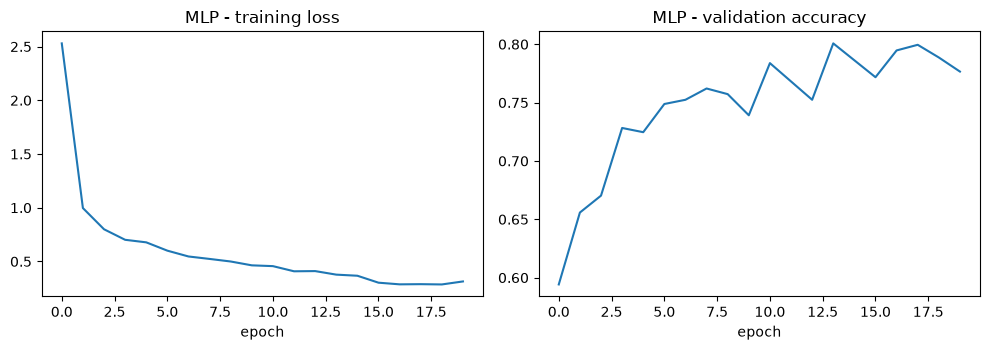

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(mlp.loss_curve_); ax[0].set_title("MLP - training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(mlp.validation_scores_); ax[1].set_title("MLP - validation accuracy"); ax[1].set_xlabel("epoch")
plt.tight_layout(); save_fig("history_mlp.png"); plt.show()

=== MLP ===   accuracy=0.8022  precision=0.8009  recall=0.8022  F1=0.7981
              precision    recall  f1-score   support

    airplane       0.83      0.89      0.86       145
         car       0.83      0.90      0.87       194
         cat       0.57      0.66      0.61       177
         dog       0.50      0.43      0.46       140
      flower       0.81      0.59      0.68       169
       fruit       0.92      0.99      0.95       200
   motorbike       0.90      0.90      0.90       158
      person       0.95      0.95      0.95       197

    accuracy                           0.80      1380
   macro avg       0.79      0.79      0.79      1380
weighted avg       0.80      0.80      0.80      1380

saved -> results\figures\cm_mlp.png


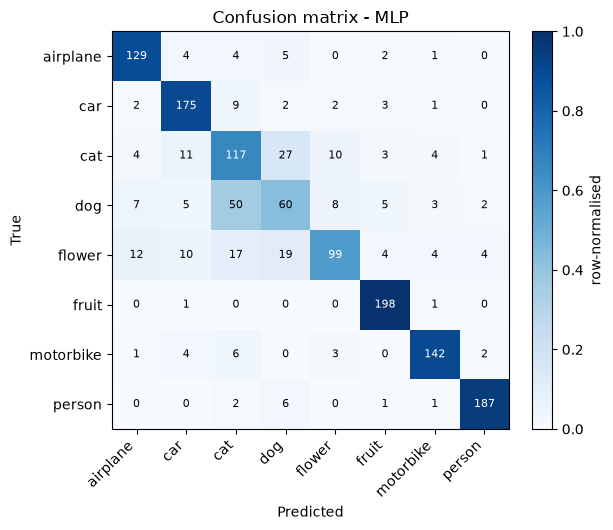

saved -> results\figures\predictions_mlp.png


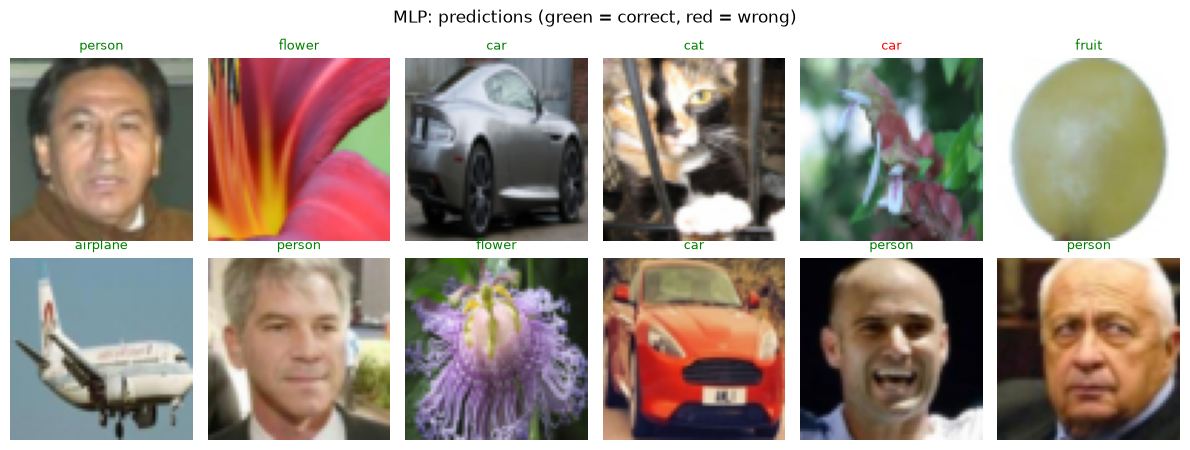

['C:\\Users\\ASUS\\Desktop\\image_classification_project\\models\\mlp.joblib']

In [6]:
y_pred = mlp.predict(Xte)
evaluate("MLP", "Deep Learning", y_test, y_pred, tt)
show_predictions(X_test, y_test, y_pred, "MLP")
joblib.dump(mlp, MODELS_DIR / "mlp.joblib")

## 2 - CNN (PyTorch, optional)
![CNN](../docs/model_steps/08_cnn.png)

Three blocks of *[Conv-BatchNorm-ReLU] x 2 -> MaxPool -> Dropout* with 32/64/128 filters, global average pooling and a small classifier,
plus light data augmentation (random horizontal flip) during training.

Install PyTorch (CPU) if you want to run it:  `python -m pip install torch`
If Windows blocks it, this cell just prints a message and you can continue.

In [7]:
try:
    import torch, torch.nn as nn
    TORCH_OK = True
    print("PyTorch", torch.__version__)
except Exception as e:                       # ImportError, or a DLL blocked by Windows
    TORCH_OK = False
    print("PyTorch is not available here ->", type(e).__name__, "\nThe CNN section is skipped.")

PyTorch 2.15.0+cpu


epoch 1/25  loss 1.126  acc 0.606  val_acc 0.736
epoch 2/25  loss 0.721  acc 0.746  val_acc 0.741
epoch 3/25  loss 0.566  acc 0.792  val_acc 0.814
epoch 4/25  loss 0.471  acc 0.827  val_acc 0.689
epoch 5/25  loss 0.386  acc 0.856  val_acc 0.871
epoch 6/25  loss 0.383  acc 0.860  val_acc 0.794
epoch 7/25  loss 0.309  acc 0.886  val_acc 0.831
epoch 8/25  loss 0.304  acc 0.887  val_acc 0.851
epoch 9/25  loss 0.276  acc 0.900  val_acc 0.860
epoch 10/25  loss 0.285  acc 0.897  val_acc 0.869
epoch 11/25  loss 0.242  acc 0.912  val_acc 0.839
epoch 12/25  loss 0.244  acc 0.909  val_acc 0.848
epoch 13/25  loss 0.232  acc 0.918  val_acc 0.868
epoch 14/25  loss 0.207  acc 0.923  val_acc 0.869
epoch 15/25  loss 0.183  acc 0.932  val_acc 0.919
epoch 16/25  loss 0.202  acc 0.923  val_acc 0.941
epoch 17/25  loss 0.187  acc 0.931  val_acc 0.919
epoch 18/25  loss 0.178  acc 0.933  val_acc 0.856
epoch 19/25  loss 0.162  acc 0.941  val_acc 0.943
epoch 20/25  loss 0.169  acc 0.936  val_acc 0.932
epoch 21/

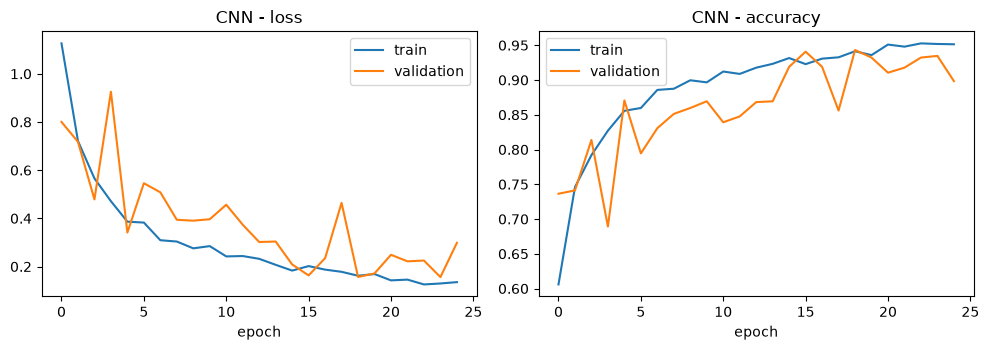

=== CNN ===   accuracy=0.9312  precision=0.9360  recall=0.9312  F1=0.9316
              precision    recall  f1-score   support

    airplane       1.00      0.85      0.92       145
         car       0.87      1.00      0.93       194
         cat       0.91      0.84      0.88       177
         dog       0.75      0.84      0.79       140
      flower       0.96      0.96      0.96       169
       fruit       0.99      1.00      0.99       200
   motorbike       0.97      0.99      0.98       158
      person       1.00      0.92      0.96       197

    accuracy                           0.93      1380
   macro avg       0.93      0.93      0.93      1380
weighted avg       0.94      0.93      0.93      1380

saved -> results\figures\cm_cnn.png


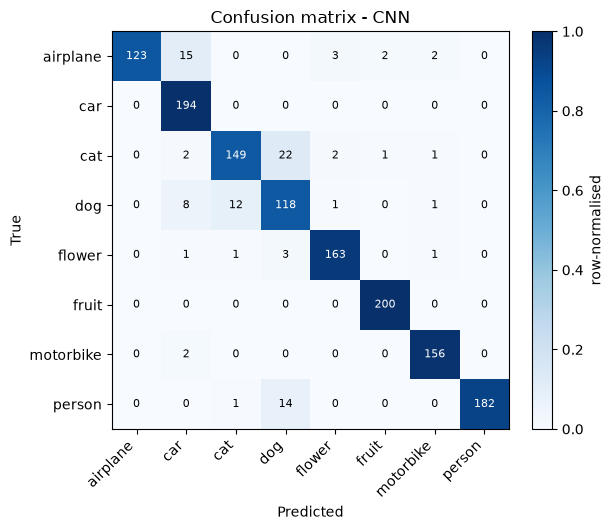

saved -> results\figures\predictions_cnn.png


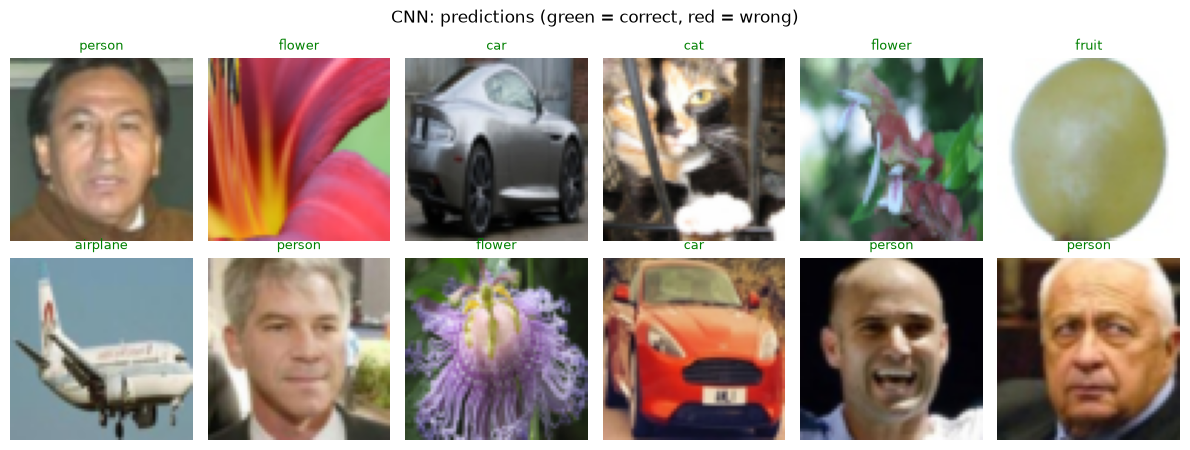

In [8]:
if TORCH_OK:
    torch.manual_seed(SEED); np.random.seed(SEED)

    def block(cin, cout):
        return nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(),
            nn.MaxPool2d(2), nn.Dropout(0.25))

    class CNN(nn.Module):
        def __init__(self):
            super().__init__()
            self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))
            self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                      nn.Linear(128, 128), nn.ReLU(), nn.Dropout(0.4),
                                      nn.Linear(128, len(CLASSES)))
        def forward(self, x): return self.head(self.features(x))

    to_t = lambda X: torch.tensor(X.astype("float32") / 255.0).permute(0, 3, 1, 2)   # NHWC -> NCHW
    Ttr, Tte = to_t(X_train), to_t(X_test)
    ytr, yte = torch.tensor(y_train), torch.tensor(y_test)
    perm = torch.randperm(len(Ttr)); n_val = int(0.15 * len(Ttr))
    val_idx, tr_idx = perm[:n_val], perm[n_val:]

    cnn = CNN(); opt = torch.optim.Adam(cnn.parameters(), 1e-3); lossf = nn.CrossEntropyLoss()
    hist = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": []}

    def run_eval(X, y):
        cnn.eval(); out = []
        with torch.no_grad():
            for i in range(0, len(X), 256): out.append(cnn(X[i:i + 256]))
        out = torch.cat(out); return lossf(out, y).item(), (out.argmax(1) == y).float().mean().item(), out

    t = time.time()
    for ep in range(EPOCHS["cnn"]):
        cnn.train(); idx = tr_idx[torch.randperm(len(tr_idx))]; tl = tc = 0
        for i in range(0, len(idx), 64):
            b = idx[i:i + 64]; xb, yb = Ttr[b], ytr[b]
            flip = torch.rand(len(xb)) < 0.5; xb = torch.where(flip[:, None, None, None], xb.flip(3), xb)   # augmentation
            opt.zero_grad(); out = cnn(xb); loss = lossf(out, yb); loss.backward(); opt.step()
            tl += loss.item() * len(b); tc += (out.argmax(1) == yb).sum().item()
        vl, va, _ = run_eval(Ttr[val_idx], ytr[val_idx])
        hist["loss"].append(tl / len(tr_idx)); hist["accuracy"].append(tc / len(tr_idx))
        hist["val_loss"].append(vl); hist["val_accuracy"].append(va)
        print(f"epoch {ep+1}/{EPOCHS['cnn']}  loss {hist['loss'][-1]:.3f}  acc {hist['accuracy'][-1]:.3f}  val_acc {va:.3f}")
    tt = time.time() - t

    class _H: pass
    h = _H(); h.history = hist; plot_history(h, "CNN")
    _, _, logits = run_eval(Tte, yte); y_pred = logits.argmax(1).numpy()
    evaluate("CNN", "Deep Learning", y_test, y_pred, tt)
    show_predictions(X_test, y_test, y_pred, "CNN")
    torch.save(cnn.state_dict(), MODELS_DIR / "cnn.pt")

saved -> results\figures\04_cnn_feature_maps.png


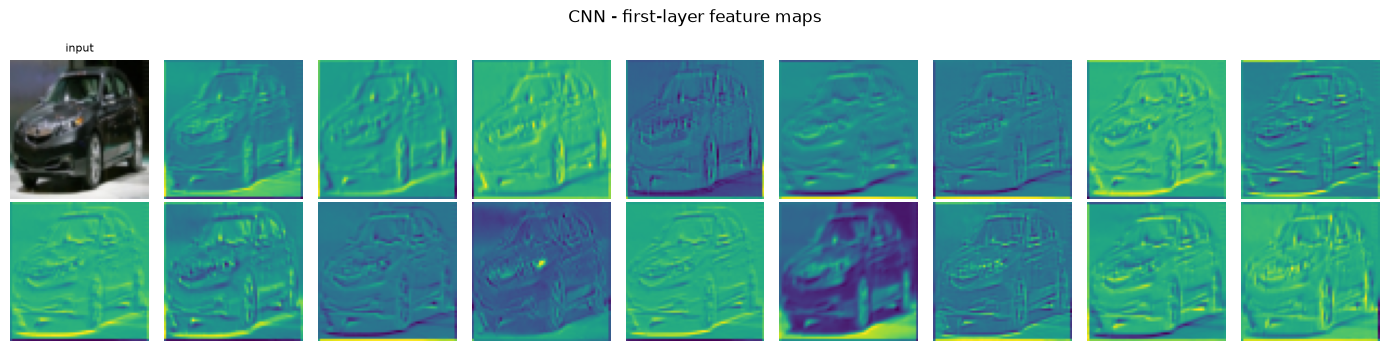

In [9]:
if TORCH_OK:
    # feature maps of the first conv layer for one test image
    cnn.eval()
    with torch.no_grad():
        fm = cnn.features[0][0](Tte[:1])[0].numpy()          # first Conv2d -> (32, 64, 64)
    fig, axes = plt.subplots(2, 9, figsize=(14, 3.6))
    for a in axes.ravel(): a.axis("off")
    axes[0, 0].imshow(X_test[0]); axes[0, 0].set_title("input", fontsize=8)
    for c, a in enumerate(axes.ravel()[1:]): a.imshow(fm[c], cmap="viridis")
    plt.suptitle("CNN - first-layer feature maps"); plt.tight_layout(); save_fig("04_cnn_feature_maps.png"); plt.show()

## Summary of this notebook

In [10]:
df = compare(); display(df[df["family"] == "Deep Learning"].round(4))

,model,family,accuracy,precision,recall,f1_score,train_time_s
0,CNN,Deep Learning,0.9312,0.9360,0.9312,0.9316,570.1
5,MLP,Deep Learning,0.8022,0.8009,0.8022,0.7981,259.2
